# ETH/USDT 动态网格回测：单均线门控 vs 无门控 vs Buy&Hold

基于 **vnpy 4.4.0** 的 `vnpy.alpha` 回测框架，在 **2021-05-01 ~ 2022-12-31**区间内对比三种策略：

1. **无门控动态网格**：现有 `DynamicGridStrategy` 原样（基准，价格跌破网格下界前持续接盘）
2. **单均线门控动态网格**：`close < MA(MA_WINDOW)` 判定**下跌行情** → **撤单观望**（保留已持仓）；行情回暖 `close >= MA` 时**以当前价重新锚定重建等距网格**
3. **Buy&Hold**：期初全仓买入持有

- 数据来源：Binance，日频 K 线缓存于 `data/eth_usdt_1d.csv`（2021-01-01 ~ 2025-12-31）
- 网格为**等距**固定价格区间 `[GRID_LOWER, GRID_UPPER]`，价格超出上下界时暂停交易（与原策略一致）
- 门控状态机与 `dynamic_grid_backtest_eth_xgb.ipynb` 的 XGBoost 门控完全同构，仅把「预测单边概率」换成「价格跌破均线」

所有可调参数集中在「参数设置」单元格，修改后从头重跑即可。


In [1]:
# ---- vnpy.alpha 可选依赖兼容处理 ----
# vnpy.alpha 包顶层会导入 alphalens / talib / torch / lightgbm 等可选依赖。
# 本项目仅使用其中的回测引擎 (BacktestingEngine) 与数据实验室 (AlphaLab)，
# 对未安装的可选依赖注入空实现，避免导入失败。
import sys
import types

_STUB_ATTRS = {
    "alphalens": {},
    "alphalens.utils": {"get_clean_factor_and_forward_returns": lambda *a, **k: None},
    "alphalens.tears": {"create_full_tear_sheet": lambda *a, **k: None},
    "talib": {},
    "torch": {},
    "torch.nn": {},
    "torch.optim": {},
    "lightgbm": {},
}
for _name, _attrs in _STUB_ATTRS.items():
    if _name in sys.modules:
        continue
    _mod = types.ModuleType(_name)
    for _k, _v in _attrs.items():
        setattr(_mod, _k, _v)
    sys.modules[_name] = _mod

# ---- 常用库 ----
import bisect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from vnpy.alpha import AlphaLab, AlphaStrategy, BacktestingEngine
from vnpy.trader.object import BarData
from vnpy.trader.constant import Direction, Exchange, Interval

# 中文字体与内联绘图
%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
})

## 1. 参数设置

回测区间扩展至 **2021-05-01 ~ 2022-12-31**（610 天），覆盖 2021 下半年冲高与 2022 完整熊市（ETH 从 4800 跌至 880）。网格上下界取区间收盘价 **5%/95% 分位** ≈ [1200, 4300]。


In [ ]:
# ================= 统一可调参数 =================

# --- 数据与回测区间 ---
DATA_PATH = "../data/eth_usdt_1d.csv"     # 日线数据路径（相对 notebook 目录）
START = "2021-05-01"                       # 回测起始日期
END = "2022-12-31"                         # 回测结束日期（覆盖 2022 熊市）

# --- 等距网格参数 ---
GRID_LOWER = 1200                          # 网格下界 (USDT)
GRID_UPPER = 4300                          # 网格上界 (USDT)
GRID_STEPS = 50                            # 网格层数
GRID_SPACING_RATIO = 1.0                   # 等距网格（=1 时 build_grid_prices 退化为均匀切分）
VOLUME_PER_GRID = 1.0                      # 每格成交数量 (ETH)
INITIAL_BASE_RATIO = 0.5                   # 初始底仓占资金比例 (0~1)

# --- 均线门控参数 ---
MA_WINDOW = 60                             # 单均线周期：close < MA(n) 判定下跌行情 -> 撤单观望

# --- 资金 / 费率 / vnpy ---
INIT_CAPITAL = 100_000                     # 初始资金 (USDT)
FEE_RATE = 0.001                           # 单边手续费率（币安现货 0.1%）
PRICE_TICK = 0.01                          # 最小价格变动
VT_SYMBOL = "ETHUSDT.GLOBAL"               # vnpy 合约代码
LAB_PATH = "../data/vnpy_lab"              # vnpy 数据实验室目录

def build_grid_prices(lower: float, upper: float, steps: int, ratio: float) -> list[float]:
    """构造网格价：ratio=1 时等距切分。"""
    if ratio >= 1:
        step = (upper - lower) / steps
        return [lower + step * i for i in range(steps + 1)]
    d1 = (upper - lower) * (1 - ratio) / (1 - ratio ** steps)
    prices = [lower + d1 * (1 - ratio ** k) / (1 - ratio) for k in range(steps)]
    prices.append(upper)
    return prices

GRID_PRICES = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, GRID_SPACING_RATIO)
_step = GRID_PRICES[1] - GRID_PRICES[0]

## 2. 数据加载与统计

读取日线数据，统计回测区间价格分布与网格覆盖天数。


全部数据行数: 1826，回测区间行数: 610
区间: 2021-05-01 ~ 2022-12-31
价格范围: 882 ~ 4866 USDT
网格区间内天数: 544 (89.2%)  |  区间外暂停天数: 66 (10.8%)


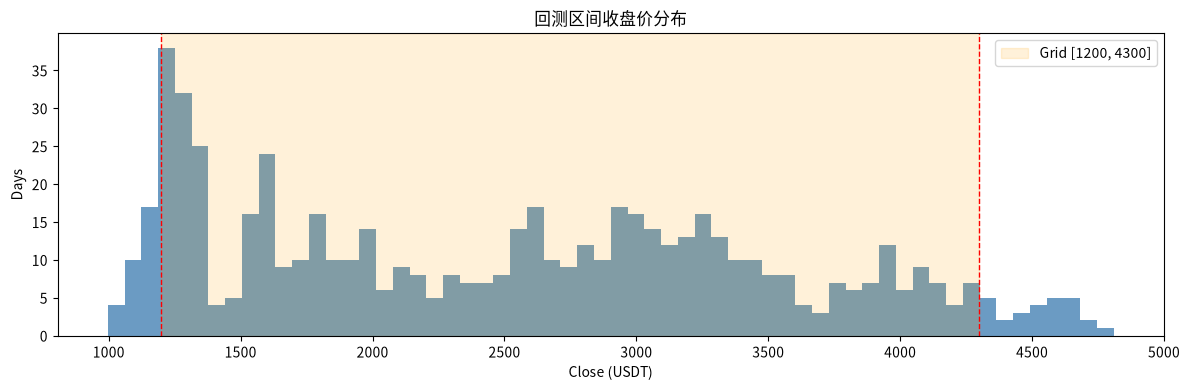

In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["pct_change"] = df["close"].pct_change()
df["daily_range"] = (df["high"] - df["low"]) / df["close"]

in_range = (df["timestamp"] >= START) & (df["timestamp"] <= END)
bdf = df[in_range].reset_index(drop=True)

print(f"全部数据行数: {len(df)}，回测区间行数: {len(bdf)}")
print(f"区间: {bdf['timestamp'].min().date()} ~ {bdf['timestamp'].max().date()}")
print(f"价格范围: {bdf['low'].min():.0f} ~ {bdf['high'].max():.0f} USDT")

n_total = len(bdf)
n_in = int(((bdf["close"] >= GRID_LOWER) & (bdf["close"] <= GRID_UPPER)).sum())
print(f"网格区间内天数: {n_in} ({n_in/n_total*100:.1f}%)  |  区间外暂停天数: {n_total-n_in} ({(n_total-n_in)/n_total*100:.1f}%)")

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(bdf["close"], bins=60, color="steelblue", alpha=0.8)
ax.axvspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.15, label=f"Grid [{GRID_LOWER}, {GRID_UPPER}]")
ax.axvline(GRID_LOWER, color="red", ls="--", lw=1)
ax.axvline(GRID_UPPER, color="red", ls="--", lw=1)
ax.set_xlabel("Close (USDT)")
ax.set_ylabel("Days")
ax.set_title("回测区间收盘价分布")
ax.legend()
plt.tight_layout()
plt.show()

## 3. 均线信号预计算

在全量历史上计算 `MA(MA_WINDOW)`（数据自 2021-01 起，`START` 前有 60+ 天预热），
构造 **门控查表** `MA_GATE_MAP = {日期: 是否下跌行情}`，其中下跌行情定义为当日 `close < MA(n)`。

策略在每个交易日按日期查表，无需在策略内部维护滚动窗口，天然避免均线热启动问题。


In [4]:
def build_ma_gate_map(window: int) -> dict[str, bool]:
    """全量历史计算 MA(window)，返回 {日期iso: close<MA 是否下跌行情} 门控映射。"""
    t = df.copy()
    t["ma"] = t["close"].rolling(window).mean()
    t["bear"] = t["close"] < t["ma"]
    return {pd.Timestamp(d).date().isoformat(): bool(b) for d, b in zip(t["timestamp"], t["bear"])}

MA_GATE_MAP = build_ma_gate_map(MA_WINDOW)

bear_all = sum(1 for b in MA_GATE_MAP.values() if b)
print(f"MA_WINDOW={MA_WINDOW}: 全历史 close<MA 天数 {bear_all}/{len(MA_GATE_MAP)} ({bear_all/len(MA_GATE_MAP):.1%})")

bear_in_bk = sum(1 for d, b in MA_GATE_MAP.items() if b and START <= d <= END)
print(f"回测区间内 close<MA 天数: {bear_in_bk}/{len(bdf)} ({bear_in_bk/len(bdf):.1%})  -> 撤单观望")

MA_WINDOW=60: 全历史 close<MA 天数 862/1826 (47.2%)
回测区间内 close<MA 天数: 361/610 (59.2%)  -> 撤单观望


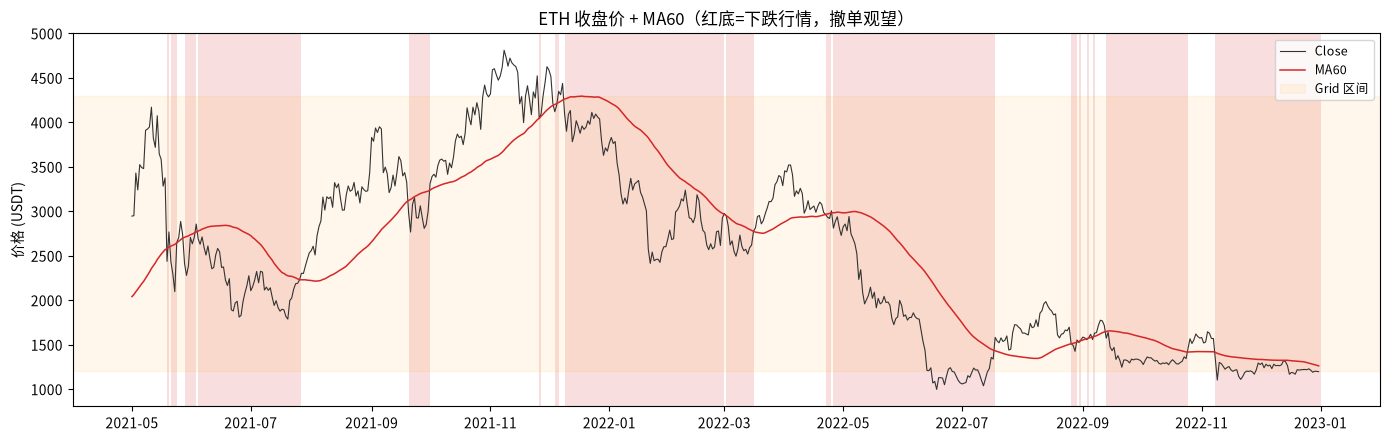

In [5]:
# 价格 + MA + 下跌行情着色（红底=close<MA，触发撤单观望）
full = df.copy()
full["ma"] = full["close"].rolling(MA_WINDOW).mean()
w = full[(full["timestamp"] >= START) & (full["timestamp"] <= END)]

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(w["timestamp"], w["close"], lw=0.8, color="#333333", label="Close")
ax.plot(w["timestamp"], w["ma"], lw=1.1, color="#d62728", label=f"MA{MA_WINDOW}")
for ts, is_bear in zip(w["timestamp"], w["close"] < w["ma"]):
    if is_bear:
        ax.axvspan(ts, ts + pd.Timedelta(days=1), color="#d62728", alpha=0.15, linewidth=0)
ax.axhspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.08, label="Grid 区间")
ax.set_title(f"ETH 收盘价 + MA{MA_WINDOW}（红底=下跌行情，撤单观望）")
ax.set_ylabel("价格 (USDT)")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 4. vnpy 数据准备

将回测区间内的 CSV 数据写入 `AlphaLab`，并登记合约交易参数（手续费 / 合约乘数 / 最小变动价位）。


In [6]:
lab = AlphaLab(LAB_PATH)
symbol = VT_SYMBOL.split(".")[0]

bars = []
for r in bdf.itertuples():
    bars.append(BarData(
        symbol=symbol,
        exchange=Exchange("GLOBAL"),
        datetime=r.timestamp.to_pydatetime(),
        interval=Interval.DAILY,
        open_price=r.open,
        high_price=r.high,
        low_price=r.low,
        close_price=r.close,
        volume=r.volume,
        gateway_name="DB",
    ))

lab.save_bar_data(bars)
lab.add_contract_setting(
    VT_SYMBOL,
    long_rate=FEE_RATE,
    short_rate=FEE_RATE,
    size=1,
    pricetick=PRICE_TICK,
)
print(f"已写入 {len(bars)} 根日线 -> {LAB_PATH}/daily/{VT_SYMBOL}.parquet")

已写入 610 根日线 -> ../data/vnpy_lab/daily/ETHUSDT.GLOBAL.parquet


## 5. 策略定义

### 5.1 无门控动态网格 `DynamicGridStrategy`（基准）

与原始 notebook 完全一致：动态挂单 + 等距网格，价格超出网格区间暂停发新单。


In [7]:
class DynamicGridStrategy(AlphaStrategy):
    """无门控动态网格：以当前价格向下最接近的网格价 Pt 为锚，上方挂卖单、下方挂买单；
    成交后反手追加挂单；价格超出网格区间时暂停发新单。等距网格（ratio=1）。"""

    grid_spacing_ratio: float = GRID_SPACING_RATIO

    def on_init(self) -> None:
        self.volume_per_grid = VOLUME_PER_GRID
        self.grid_prices = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, self.grid_spacing_ratio)

        self.standing_sells: dict[float, float] = {}
        self.standing_buys: dict[float, float] = {}
        self.order_level: dict[str, float] = {}
        self.roll_to_buy: list[float] = []
        self.roll_to_sell: list[float] = []

        self.base_pos_done: bool = False
        self.pending_base_vol: float = 0.0
        self.pending_base_cost: float = 0.0

    def floor_grid(self, price: float) -> float:
        idx = bisect.bisect_right(self.grid_prices, price) - 1
        return self.grid_prices[max(idx, 0)]

    def sell_capacity(self) -> float:
        pending = self.pending_base_vol if self.pending_base_cost > 0 else 0.0
        return self.get_pos(VT_SYMBOL) + pending

    def buy_cash(self) -> float:
        pending = self.pending_base_cost if self.pending_base_cost > 0 else 0.0
        return self.get_cash_available() - pending

    def place_sell_at(self, price: float, vol: float) -> float:
        committed = sum(self.standing_sells.values())
        avail = max(0.0, self.sell_capacity() - committed)
        vol = min(vol, avail)
        if vol > 0:
            oids = self.sell(VT_SYMBOL, price, vol)
            self.standing_sells[price] = self.standing_sells.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def place_buy_at(self, price: float, vol: float) -> float:
        committed = sum(p * v for p, v in self.standing_buys.items())
        avail_cash = max(0.0, self.buy_cash() - committed)
        vol = min(vol, avail_cash / (price * (1 + FEE_RATE)))
        if vol > 0:
            oids = self.buy(VT_SYMBOL, price, vol)
            self.standing_buys[price] = self.standing_buys.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return
        close = bar.close_price

        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
                self.pending_base_vol = base_vol
                self.pending_base_cost = base_vol * close
            self.base_pos_done = True

            anchor = self.floor_grid(close)
            for p in self.grid_prices:
                if p > anchor:
                    self.place_sell_at(p, self.volume_per_grid)
            for p in self.grid_prices:
                if p < anchor:
                    self.place_buy_at(p, self.volume_per_grid)
            return

        if not (GRID_LOWER <= close <= GRID_UPPER):
            return

        for p in self.roll_to_buy:
            self.place_buy_at(p, self.volume_per_grid)
        self.roll_to_buy.clear()
        for p in self.roll_to_sell:
            self.place_sell_at(p, self.volume_per_grid)
        self.roll_to_sell.clear()

    def on_trade(self, trade) -> None:
        self.write_log(f"成交 {trade.direction.value} {trade.volume:.4f} @ {trade.price:.2f}")

        level = self.order_level.pop(trade.vt_orderid, None)
        if level is None:
            self.pending_base_vol = 0.0
            self.pending_base_cost = 0.0
            return

        if trade.direction == Direction.LONG:
            self.standing_buys[level] -= trade.volume
            if self.standing_buys[level] <= 1e-9:
                del self.standing_buys[level]
            self.roll_to_sell.append(level)
        else:
            self.standing_sells[level] -= trade.volume
            if self.standing_sells[level] <= 1e-9:
                del self.standing_sells[level]
            self.roll_to_buy.append(level)

### 5.2 单均线门控动态网格 `MAGatedGridStrategy`

在无门控策略基础上增加**状态机**（撤单观望 + 重建网格）：

```
GRID(均线上方): 正常网格交易
  └ 下跌行情 close < MA(n) ──► SUSPENDED: cancel_all() + 清空挂单簿/追加队列；底仓保留不动
SUSPENDED(下跌行情): 不做任何交易
  └ 行情回暖 close >= MA(n) ──► GRID: 以当前收盘价 floor_grid 重新锚定，重建完整等距网格
```

- 门控查表：每个交易日查预计算的 `MA_GATE_MAP`
- `cancel_all()` 在 vnpy 回测中真实生效（挂单置 CANCELLED，不再成交）
- 底仓在下跌期间保留（不做主动止损），恢复时继续作为持仓；重建卖单数量以上限 = 实际持仓


In [8]:
class MAGatedGridStrategy(DynamicGridStrategy):
    """单均线门控动态网格：close < MA(MA_WINDOW) 判定下跌行情 -> 撤单观望（保留底仓）；
    行情回暖 close >= MA -> 以当前收盘价重新锚定重建完整网格挂单簿。"""

    def on_init(self) -> None:
        super().on_init()
        self.state = "GRID"          # GRID(均线上方) / SUSPENDED(下跌撤单观望)

    def _bear_market(self, bar) -> bool:
        """查表：close < MA(n) 判定下跌行情。无 MA 值（理论上不存在）默认非下跌。"""
        key = bar.datetime.date().isoformat()
        return MA_GATE_MAP.get(key, False)

    def _rebuild_grid(self, close: float) -> None:
        """以当前收盘价 floor_grid 重新锚定，重建完整挂单簿。"""
        self.cancel_all()
        self.standing_sells.clear()
        self.standing_buys.clear()
        self.order_level.clear()
        self.roll_to_buy.clear()
        self.roll_to_sell.clear()
        anchor = self.floor_grid(close)
        for p in self.grid_prices:
            if p > anchor:
                self.place_sell_at(p, self.volume_per_grid)
            if p < anchor:
                self.place_buy_at(p, self.volume_per_grid)

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return

        # 首日：与无门控一致（建底仓 + 初始网格），随后立即做一次门控判定，
        # 若首日即下跌行情则撤掉全部挂单（含未成交底仓）进入观望
        if not self.base_pos_done:
            super().on_bars(bars)
            if self._bear_market(bar):
                self.cancel_all()
                self.standing_sells.clear()
                self.standing_buys.clear()
                self.order_level.clear()
                self.roll_to_buy.clear()
                self.roll_to_sell.clear()
                self.pending_base_vol = 0.0
                self.pending_base_cost = 0.0
                self.state = "SUSPENDED"
            return

        is_bear = self._bear_market(bar)

        if is_bear and self.state == "GRID":
            # 下跌行情来临：撤单观望（底仓保留）
            self.cancel_all()
            self.standing_sells.clear()
            self.standing_buys.clear()
            self.order_level.clear()
            self.roll_to_buy.clear()
            self.roll_to_sell.clear()
            self.state = "SUSPENDED"
            return

        if not is_bear and self.state == "SUSPENDED":
            # 行情回暖：重新锚定重建
            self.state = "GRID"
            self._rebuild_grid(bar.close_price)
            return

        if self.state == "SUSPENDED":
            return

        super().on_bars(bars)

## 6. 回测执行

用 `vnpy.alpha` 的 `BacktestingEngine` 回放日线，三策略在**同一区间、同一参数**下各跑一次。


In [9]:
from loguru import logger as _loguru

def run_backtest(strategy_class, label):
    """运行一次回测，返回 engine。"""
    engine = BacktestingEngine(lab)
    engine.set_parameters(
        vt_symbols=[VT_SYMBOL],
        interval=Interval.DAILY,
        start=pd.Timestamp(START).to_pydatetime(),
        end=pd.Timestamp(END).to_pydatetime(),
        capital=INIT_CAPITAL,
        risk_free=0,
        annual_days=252,
    )
    engine.add_strategy(strategy_class, {}, pl.DataFrame())
    engine.load_data()
    _loguru.disable("vnpy.alpha")
    engine.run_backtesting()
    engine.calculate_result()
    engine.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    return engine

eng_plain = run_backtest(DynamicGridStrategy, "无门控")
print("无门控网格回测完成")

eng_ma = run_backtest(MAGatedGridStrategy, "MA门控")
print("MA门控网格回测完成")

2026-08-12 00:44:29 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 276.87it/s]

2026-08-12 00:44:29 所有历史数据加载完成


无门控网格回测完成
2026-08-12 00:44:29 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 416.89it/s]

2026-08-12 00:44:29 所有历史数据加载完成


MA门控网格回测完成


In [10]:
# ---- Buy&Hold 基准：期初全仓买入持有 ----
bh_shares = INIT_CAPITAL / bdf["close"].iloc[0]
bh_equity = bh_shares * bdf["close"]
bh_ret = bh_equity.iloc[-1] / INIT_CAPITAL - 1
print(f"Buy&Hold: 期初 {INIT_CAPITAL:,} USDT @ {bdf['close'].iloc[0]:.2f} -> 期末 {bh_equity.iloc[-1]:,.0f} USDT")
print(f"总收益率: {bh_ret:.1%}")

Buy&Hold: 期初 100,000 USDT @ 2945.37 -> 期末 40,608 USDT
总收益率: -59.4%


## 7. 结果对比

### 7.1 指标表

对比总收益、年化收益、最大回撤、夏普、成交笔数等。核心观察：MA 门控是否显著降低**买入笔数**（少接盘）并改善最大回撤。


In [11]:
import IPython.display as ipd

def summarize(engine, label):
    _loguru.disable("vnpy.alpha")
    st = engine.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    trades = engine.get_all_trades()
    buy_cnt = sum(1 for t in trades if t.direction == Direction.LONG)
    sell_cnt = len(trades) - buy_cnt
    return {
        "策略": label,
        "总收益率%": round(st["total_return"], 2),
        "年化收益%": round(st["annual_return"], 2),
        "最大回撤%": round(st["max_ddpercent"], 2),
        "Sharpe": round(st["sharpe_ratio"], 2),
        "期末余额": round(st["end_balance"], 0),
        "成交笔数": len(trades),
        "买入/卖出": f"{buy_cnt}/{sell_cnt}",
    }

bh_max_dd = float((bh_equity / bh_equity.cummax() - 1).min() * 100)
rows = [
    summarize(eng_plain, "无门控网格"),
    summarize(eng_ma, "MA门控网格"),
    {
        "策略": "Buy&Hold",
        "总收益率%": round(bh_ret * 100, 2),
        "年化收益%": round(((1 + bh_ret) ** (365 / len(bdf)) - 1) * 100, 2),
        "最大回撤%": round(bh_max_dd, 2),
        "Sharpe": np.nan,
        "期末余额": round(bh_equity.iloc[-1], 0),
        "成交笔数": 1,
        "买入/卖出": "1/0",
    },
]
df_cmp = pd.DataFrame(rows)
ipd.display(df_cmp)

,策略,总收益率%,年化收益%,最大回撤%,Sharpe,期末余额,成交笔数,买入/卖出
0,无门控网格,11.06,4.57,-38.28,0.29,111061.0,1626,827/799
1,MA门控网格,19.54,8.07,-27.94,0.40,119540.0,827,419/408
2,Buy&Hold,-59.39,-41.68,-79.28,NaN,40608.0,1,1/0


### 7.2 净值曲线对比

三策略净值归一化到初始资金 100,000。门控网格的净值应在 2022 熊市中更平稳（下跌段撤单规避逆势买入）。


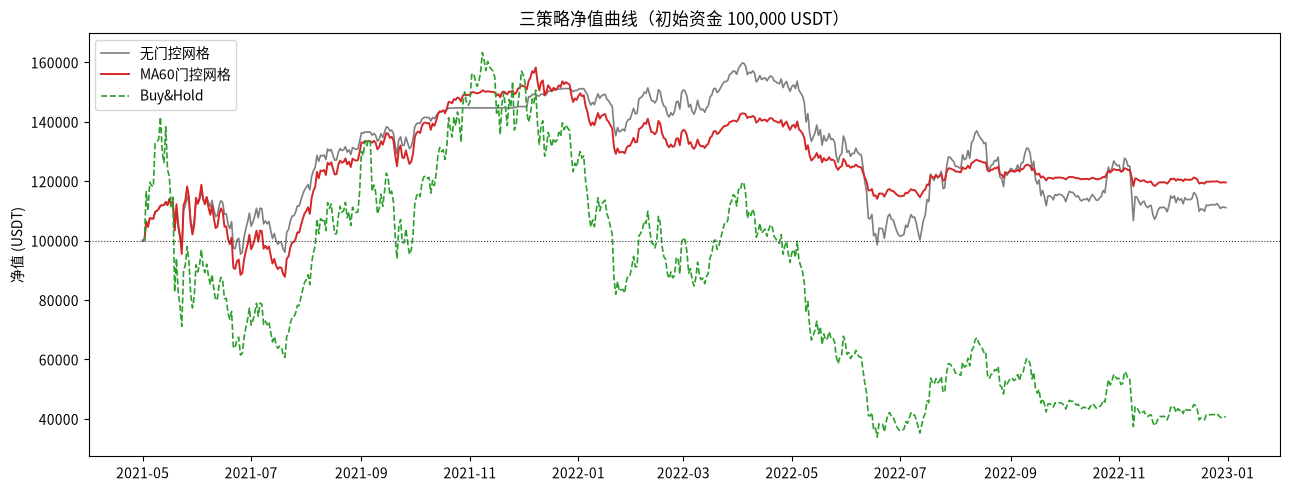

In [12]:
def daily_balance(engine):
    """从 engine.daily_df（polars）提取逐日余额。"""
    ddf = engine.daily_df
    dates = pd.to_datetime(ddf["date"].to_list())
    balance = np.cumsum(ddf["net_pnl"].to_list()) + INIT_CAPITAL
    return pd.Series(balance, index=dates)

bal_plain = daily_balance(eng_plain)
bal_ma = daily_balance(eng_ma)
bh_series = pd.Series(bh_equity.values, index=bdf["timestamp"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(bal_plain.index, bal_plain.values, lw=1.2, color="#7f7f7f", label="无门控网格")
ax.plot(bal_ma.index, bal_ma.values, lw=1.4, color="#d62728", label=f"MA{MA_WINDOW}门控网格")
ax.plot(bh_series.index, bh_series.values, lw=1.2, color="#2ca02c", ls="--", label="Buy&Hold")
ax.axhline(INIT_CAPITAL, color="#333", ls=":", lw=0.8)
ax.set_title("三策略净值曲线（初始资金 100,000 USDT）")
ax.set_ylabel("净值 (USDT)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 7.3 门控撤单段与净值的直观对照

红底 = `close < MA` 的下跌行情（撤单观望段）。观察：无门控网格在该段仍在接盘（买入笔数激增、净值下滑），
门控网格则停止新买入，净值更平稳。


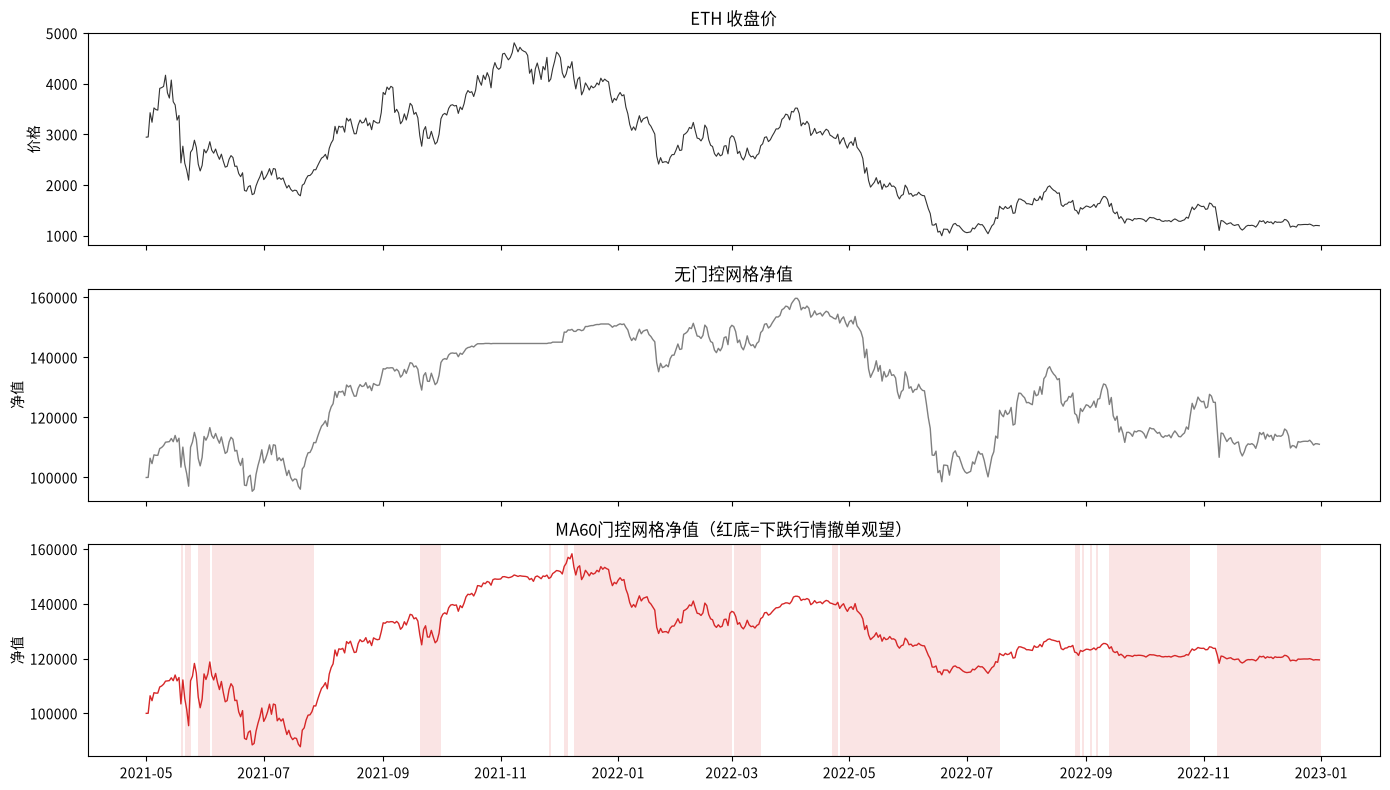

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(bdf["timestamp"], bdf["close"], lw=0.8, color="#333333")
axes[0].set_title("ETH 收盘价")
axes[0].set_ylabel("价格")

axes[1].plot(bal_plain.index, bal_plain.values, lw=1, color="#7f7f7f")
axes[1].set_title("无门控网格净值")
axes[1].set_ylabel("净值")

axes[2].plot(bal_ma.index, bal_ma.values, lw=1, color="#d62728")
for d, b in MA_GATE_MAP.items():
    if b and START <= d <= END:
        axes[2].axvspan(pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta(days=1),
                        color="#d62728", alpha=0.12, linewidth=0)
axes[2].set_title(f"MA{MA_WINDOW}门控网格净值（红底=下跌行情撤单观望）")
axes[2].set_ylabel("净值")

plt.tight_layout()
plt.show()

## 8. MA_WINDOW 参数敏感性

不同均线周期下门控的取舍：**均线越短** → 对下跌反应越灵敏、观望天数越多，但也更容易在震荡中被假突破骗过（反复撤单/重建）；
**均线越长** → 越稳健但越滞后，可能错过顶部出货机会、在下跌后期才触发观望。

对比不同 `MA_WINDOW` 下的收益、回撤、夏普与**买入笔数**，观察「少接盘」的效果。


In [14]:
sweep_rows = []
for wnd in [10, 20, 30, 60, 90]:
    MA_GATE_MAP = build_ma_gate_map(wnd)
    bear_n = sum(1 for d, b in MA_GATE_MAP.items() if b and START <= d <= END)

    eng_s = run_backtest(MAGatedGridStrategy, f"MA{wnd}")
    _loguru.disable("vnpy.alpha")
    st_s = eng_s.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    trades_s = eng_s.get_all_trades()
    buy_cnt = sum(1 for t in trades_s if t.direction == Direction.LONG)
    sell_cnt = len(trades_s) - buy_cnt

    sweep_rows.append({
        "MA_WINDOW": wnd,
        "观望天数": bear_n,
        "总收益率%": round(st_s["total_return"], 2),
        "最大回撤%": round(st_s["max_ddpercent"], 2),
        "Sharpe": round(st_s["sharpe_ratio"], 2),
        "买入笔数": buy_cnt,
        "卖出笔数": sell_cnt,
        "总笔数": len(trades_s),
    })

# 恢复默认门控
MA_GATE_MAP = build_ma_gate_map(MA_WINDOW)
ipd.display(pd.DataFrame(sweep_rows))

2026-08-12 00:44:30 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 396.51it/s]

2026-08-12 00:44:30 所有历史数据加载完成


2026-08-12 00:44:30 开始加载历史数据


...

2026-08-12 00:44:30 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 410.36it/s]

2026-08-12 00:44:30 所有历史数据加载完成


,MA_WINDOW,观望天数,总收益率%,最大回撤%,Sharpe,买入笔数,卖出笔数,总笔数
0,10,314,5.26,-16.90,0.23,210,217,427
1,20,341,20.73,-19.51,0.59,288,297,585
2,30,367,26.67,-27.02,0.51,331,334,665
3,60,361,19.54,-27.94,0.40,419,408,827
4,90,345,33.57,-22.76,0.60,466,460,926


## 9. 结论

基于同一区间（2021-05-01 ~ 2022-12-31，覆盖 2022 完整熊市）的实测对比，实测结果如下：

### 9.1 门控是否改善风控 / 是否牺牲收益（MA60 vs 无门控）

| 指标 | 无门控网格 | MA60门控网格 | Buy&Hold |
|---|---|---|---|
| 总收益率 | 11.06% | **19.54%** | -59.39% |
| 年化收益 | 4.57% | **8.07%** | -41.68% |
| 最大回撤 | -38.28% | **-27.94%** | -79.28% |
| Sharpe | 0.29 | **0.40** | — |
| 期末余额 | 111,061 | **119,540** | 40,608 |
| 成交笔数 | 1626 | 827 | 1 |
| 买入笔数 | 827 | **419** | 1 |

- **少接盘**：买入笔数从 827 降至 419（接近减半）——`close < MA60` 的 361 天里撤单观望，避免了在 2022 熊市（ETH 从 4800 跌至 880）持续向下接盘
- **回撤改善**：最大回撤从 -38.3% 收窄至 -27.9%，净值曲线在 2022 年显著更平稳
- **未牺牲收益**：门控网格总收益反而更高（19.5% vs 11.1%）——下跌段保住了现金，2021 年震荡段（5~7 月、8 月回升）的网格获利能力几乎完整保留
- **Buy&Hold 对照**：区间内 ETH 下跌 -59.4%，两种网格均大幅跑赢长期持有

### 9.2 MA_WINDOW 敏感性（扫掠表见第 8 节）

| MA_WINDOW | 观望天数 | 总收益率% | 最大回撤% | Sharpe | 买入笔数 |
|---|---|---|---|---|---|
| 10 | 314 | 5.26 | **-16.90** | 0.23 | 210 |
| 20 | 341 | 20.73 | -19.51 | **0.59** | 288 |
| 30 | 367 | 26.67 | -27.02 | 0.51 | 331 |
| 60 | 361 | 19.54 | -27.94 | 0.40 | 419 |
| 90 | 345 | **33.57** | -22.76 | **0.60** | 466 |

- **均线越短 → 风控越优先**：MA10 观望天数多、回撤最小（-16.9%）、买入最少（210 笔），但频繁进出反复撤单/重建，收益最低（5.3%）
- **均线越长 → 收益越优先**：MA90 收益与夏普最优（33.6% / 0.60），因滞后较长，2021-11 高位段仍持有卖单兑现盈利，2022 年中才触发观望
- **折中**：MA20 以 -19.5% 回撤取得 0.59 夏普，是回撤/收益最均衡的选择

### 9.3 关键注意

`close < MA(n)` 是**当期已知的客观信号，无前视偏差**；但均线本身滞后，门控效果高度依赖均线周期与行情节奏（本区间 MA90 最优，换一段行情可能反转），结果只反映 2021-05 ~ 2022-12 这一历史区间。


In [15]:
print("回测完成。三策略指标见上方表格，净值曲线与门控段见上图，MA_WINDOW 敏感性见扫描表。")

回测完成。三策略指标见上方表格，净值曲线与门控段见上图，MA_WINDOW 敏感性见扫描表。
